# W8_01 : Run your own BO on ALBATROSS data
ALBATROSS is our robot that mixes electrolytes and assembles coin cells. It uses Bayesian optimization (BO) to choose which electrolytes to test next.

After a short review of BO, you will run BO on real ALBATROSS data: first with two inputs (fixed volume), then with three. You will submit your 20 experiments with the highest capacity on KLMS.

Fill in each ___ in the code, then run the cell.

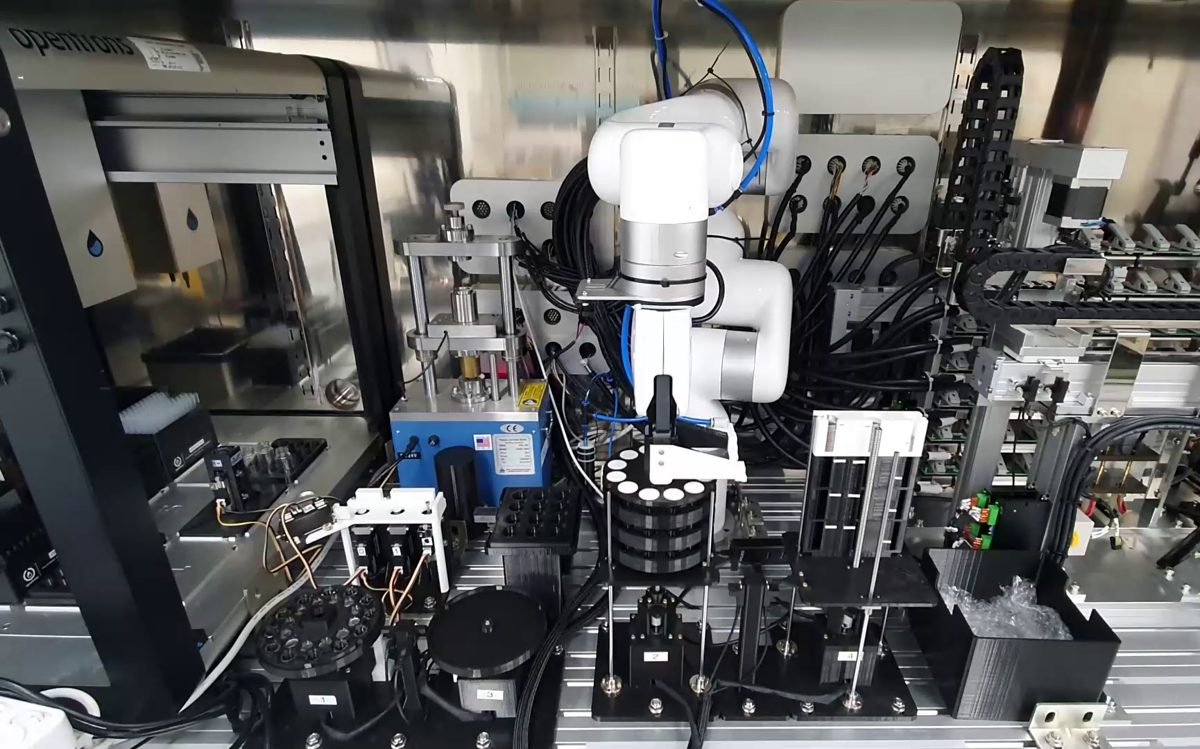


In [ ]:
#@title 1. Setup — click ▶ to start
# Helper code for this lab. Nothing to edit here.

import base64
import json
import os
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import HTML, Javascript, display
from scipy.stats import norm, qmc
from sklearn.exceptions import ConvergenceWarning
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel

# ---------- blanks (___) and ✅/❌ messages ----------
from IPython import get_ipython
from IPython.display import HTML, display


class BlankError(Exception):
    """A ___ is still in the cell."""


class _Blank:
    __array_ufunc__ = None  # numpy hands arithmetic back to us -> friendly stop

    def __repr__(self):
        return '___'

    def _stop(self, *args, **kwargs):
        raise BlankError('Replace every ___ in this cell with your answer, then run the cell again.')

    __add__ = __radd__ = __sub__ = __rsub__ = __mul__ = __rmul__ = __truediv__ = __rtruediv__ = _stop
    __pow__ = __rpow__ = __neg__ = __float__ = __int__ = __index__ = __bool__ = _stop
    __lt__ = __le__ = __gt__ = __ge__ = __call__ = __getitem__ = __iter__ = __len__ = _stop


___ = _Blank()


def has_blank(v):
    if isinstance(v, _Blank):
        return True
    if isinstance(v, dict):
        return any(has_blank(x) for x in v.values())
    if isinstance(v, (list, tuple)):
        return any(has_blank(x) for x in v)
    return False


def need(**values):
    """Stop with a friendly message if any value is (or contains) ___."""
    for name, v in values.items():
        if has_blank(v):
            raise BlankError(f'Fill in <b>{name}</b> (it still has ___), then run the cell again.')


def _say(color, text):
    display(HTML(f'<div style="border-left:5px solid {color};padding:6px 12px;margin:6px 0;font-size:14px">{text}</div>'))


def ok(text):
    _say('#3A9D5D', '✅ ' + text)


def bad(text):
    _say('#D9534F', '❌ ' + text)


def _friendly(shell, etype, evalue, tb, tb_offset=None):
    _say('#E8833A', '✋ ' + str(evalue))


if get_ipython() is not None:
    get_ipython().set_custom_exc((BlankError,), _friendly)

SERVER = os.environ.get('W8_SERVER', 'https://script.google.com/macros/s/AKfycbyzStxQU_pgYDat_HZ--BL3e4GdCFbPVIpXQLQLjE5ZqxSa9RYDjwIuPG6F3PRKgiuRFg/exec')  # the ALBATROSS data server
VIDEO = os.environ.get('W8_VIDEO', 'https://drive.google.com/uc?export=download&id=1pnXg0XebjnzBsq19iatDTras2j_XLFaN')     # ALBATROSS makes a coin cell and puts it on test (10 s)
LO, HI = np.array([1, 0.1, 5]), np.array([9, 1.5, 35])
NAMES = ['DME', 'LiPF6_M', 'volume_uL']
ORANGE, BLUE, GREY, GREEN = '#E8833A', '#2F6DB5', '#C9CED6', '#3A9D5D'
MODE = {'2D': dict(dims=2, pool=2048, per_round=10, wait='1 day of cycling per round = 10 s here'),  # 10 cells x 4 rounds
        '3D': dict(dims=3, pool=4096, per_round=20, wait='1 hour of testing per round = 7 s here')}  # 20 cells x 4 rounds


def can_mix(dme, salt):
    """Can the robot make DME:FEC = dme:(10-dme) with `salt` M LiPF6 from its stocks
    (LiPF6 0.5 M in DME, LiPF6 2.25 M in FEC, pure DME, pure FEC)? Same rule as the ALBATROSS planner."""
    fec = 10 - dme
    max_d, max_f = 0.5 * dme / 10, 2.25 * fec / 10  # mol LiPF6 each salt stock can bring to 1 L
    if max_d + max_f <= salt:
        return False
    if salt <= max_d:
        mol_d, mol_f = salt, 0.0
    elif salt <= max_f:
        mol_d, mol_f = 0.0, salt
    else:
        mol_d = 0.9 * max_d
        mol_f = salt - mol_d
    v_d, v_f = mol_d / 0.5, mol_f / 2.25  # L of each salt stock
    salt_l = 151.905 / 1.5 / 1000  # L taken up by 1 mol LiPF6
    solvent_d, solvent_f = v_d - mol_d * salt_l, v_f - mol_f * salt_l
    rest = 1 - v_d - v_f  # L of pure solvents still to add
    pure_d = (dme * rest + dme * solvent_f - fec * solvent_d) / 10
    return pure_d >= 0 and rest - pure_d >= 0


# ---------- the ALBATROSS data server ----------
class ServerError(Exception):
    """The ALBATROSS data server refused a request or could not be reached."""


def _call(**q):
    """POST one request to the server; retry a few times if the network or the server is busy."""
    for attempt in range(6):
        try:
            out = requests.post(SERVER, data=json.dumps(q), timeout=60).json()
        except (requests.RequestException, ValueError):
            time.sleep(min(2 ** attempt, 10))
            continue
        if 'error' in out:
            raise ServerError(f"ALBATROSS data server: {out['error']}")
        return out
    raise ServerError('Cannot connect to the ALBATROSS data server. Check your internet connection and run the cell again.')


if get_ipython() is not None and '_friendly' in globals():  # notebook: server problems get the same ✋ message
    get_ipython().set_custom_exc((BlankError, ServerError), _friendly)

_CLIP = None
CLIP_S = 10.04  # clip length (s); one playback = one round


def _video():
    """ALBATROSS making a coin cell and putting it on test, as an HTML <video> (downloaded once).
    It does not loop: _play() starts it at the start of every round, sped up so that it ends with the round,
    and _done() pops a '+k' badge when the round's k results arrive (the same moment the table updates)."""
    global _CLIP
    if _CLIP is None:
        try:
            raw = open(VIDEO, 'rb').read() if os.path.exists(VIDEO) else requests.get(VIDEO, timeout=60).content
            _CLIP = base64.b64encode(raw).decode() if raw[4:8] == b'ftyp' else ''
        except (OSError, requests.RequestException):
            _CLIP = ''
    if not _CLIP:
        return '<p style="color:#888">ALBATROSS is testing your cells…</p>'
    return f'''<div style="position:relative;display:inline-block;max-width:100%">
<video id="alb-video" src="data:video/mp4;base64,{_CLIP}" muted playsinline preload="auto"
 style="width:460px;max-width:100%;border-radius:6px;display:block"></video>
<div id="alb-plus" style="position:absolute;top:10px;right:12px;padding:2px 14px;border-radius:16px;background:#E8833A;
 color:#fff;font:700 28px/1.3 sans-serif;opacity:0;transform:scale(.6);transition:opacity .25s,transform .25s">+1</div>
</div>
<script>
document.getElementById('alb-video').addEventListener('ended', () => {{
  const p = document.getElementById('alb-plus');
  p.style.opacity = 1;
  p.style.transform = 'scale(1)';
}});
</script>'''


def _play(ctl, k, seconds):
    """Start the clip so that it ends about 1 s before this round's results arrive: the clip ends, '+k' pops up
    on it, and a moment later the k new results appear in the status line and the plot."""
    _js(ctl, "var v=document.getElementById('alb-video'),p=document.getElementById('alb-plus');"
             f"if(v){{p.textContent='+{k}';p.style.opacity=0;p.style.transform='scale(.6)';"
             f"v.playbackRate={CLIP_S / max(seconds - 1.0, 1):.4f};v.currentTime=0;v.play();}}")


def _done(ctl, k):
    """Fallback: the round's k results are in, so make sure '+k' shows even if the clip has not ended yet."""
    _js(ctl, f"var p=document.getElementById('alb-plus');if(p){{p.textContent='+{k}';p.style.opacity=1;"
             "p.style.transform='scale(1)';}")


def _js(ctl, js):
    try:
        from google.colab import output  # Colab: run it in this cell's output frame
        output.eval_js(js, ignore_result=True)
    except ImportError:
        ctl.update(Javascript(js))       # Jupyter


# ---------- surrogate ----------
def _fit(X, y, ls_max, restarts=2):
    """GP on inputs in [0, 1] and standardised y; one length scale per input, between 0.05 and ls_max; noise learned."""
    m, s = y.mean(), y.std() or 1.0
    kernel = (ConstantKernel(1.0, (1e-2, 1e2))
              * Matern(length_scale=[min(0.3, ls_max)] * X.shape[1], length_scale_bounds=(0.05, ls_max), nu=2.5)
              + WhiteKernel(0.1, (1e-6, 1.0)))
    gp = GaussianProcessRegressor(kernel, n_restarts_optimizer=restarts, random_state=0)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ConvergenceWarning)
        gp.fit(X, (y - m) / s)
    gp.y_mean, gp.y_std = m, s
    return gp


def acquisition(mu, sd, best, acq, value):
    if acq == 'UCB':
        return mu + np.sqrt(value) * sd
    z = (mu - best - value) / np.maximum(sd, 1e-12)
    return (mu - best - value) * norm.cdf(z) + sd * norm.pdf(z)  # EI


def greedy(mu, cov, best, acq, value, noise, n=3):
    """2-3 toy: pick n points one by one; after each pick, shrink the variance as if it had been measured."""
    var, U, picks = np.diag(cov).copy(), np.zeros((n, len(mu))), []
    for k in range(n):
        score = np.round(acquisition(mu, np.sqrt(np.clip(var, 0, None)), best, acq, value), 9)
        score[picks] = -np.inf
        i = int(np.argmax(score))  # ties -> lowest index
        picks.append(i)
        c = cov[:, i] - U[:k].T @ U[:k, i]
        U[k] = c / np.sqrt(c[i] + noise)
        var -= U[k] ** 2
    return picks


def _round_picks(gp, P, free, n, acq, value):
    """Pick n candidates for one round (kriging believer): after each pick, pretend it was measured at its mean."""
    noise = gp.kernel_.k2.noise_level
    Xf, yf, best, picks, g = gp.X_train_, gp.y_train_, gp.y_train_.max(), [], gp
    for _ in range(n):
        if picks:
            g = GaussianProcessRegressor(gp.kernel_, optimizer=None).fit(Xf, yf)
        mu, sd = g.predict(P, return_std=True)
        sd = np.sqrt(np.clip(sd ** 2 - noise, 0, None))  # uncertainty of the true capacity (noise removed)
        score = acquisition(mu, sd, best, acq, value)
        score[~free] = -np.inf
        i = int(np.argmax(score))
        picks.append(i)
        free[i] = False
        Xf, yf = np.vstack([Xf, P[i]]), np.append(yf, mu[i])
    return picks


# ---------- notebook ----------
def label(s):
    key = 'beta' if s['acq'] == 'UCB' else 'xi'
    return f"{s['acq']} {key}={s[key]:g} · ls_max={s['ls_max']:g} · {s['cells_per_round']} cells/round"


def check(s, name, fixed, n_vars):
    """fixed: cells per round set by the lab (MODE[...]['per_round']), so the student does not choose it."""
    eg = "e.g. dict(acq='UCB', beta=1.0, ls_max=0.3)"
    if not isinstance(s, dict) or s.get('acq') not in ('UCB', 'EI'):
        return bad(f"{name}: acq must be 'UCB' or 'EI', {eg}.")
    key = 'beta' if s['acq'] == 'UCB' else 'xi'
    if not isinstance(s.get(key), (int, float)) or s[key] < 0:
        return bad(f"{name}: {s['acq']} needs <code>{key}=</code> with a number 0 or greater (UCB uses beta, EI uses xi).")
    if not isinstance(s.get('ls_max'), (int, float)) or s['ls_max'] <= 0.05:
        return bad(f'{name}: ls_max must be a number greater than 0.05, e.g. 0.3.')
    if s.get('cells_per_round', fixed) != fixed:
        return bad(f'{name}: In {n_vars}-variable BO, ALBATROSS always tests {fixed} cells per round. Remove <code>cells_per_round</code>.')
    return True


def _pool(mode):
    """Candidate recipes BO can choose from: a dense Sobol set inside the ranges, only mixes the robot can make.
    A new random set for every run, so two students never end with exactly the same recipes."""
    d = MODE[mode]['dims']
    P = LO[:d] + qmc.Sobol(d).random(MODE[mode]['pool']) * (HI[:d] - LO[:d])
    P = np.column_stack([np.round(P[:, i], k) for i, k in enumerate([2, 3, 1][:d])])  # robot-friendly decimals
    return P[[can_mix(a, b) for a, b in P[:, :2]]]


def _ratio_axis(ax):
    ax.set_xticks(range(1, 10), [f'{d}:{10 - d}' for d in range(1, 10)], fontsize=8)
    ax.set(xlabel='DME:FEC', ylabel='LiPF₆ (M)', xlim=(0.6, 9.4), ylim=(0, 1.6))


def recipe(r, mode):
    """'DME:FEC 8.6:1.4 · 0.52 M LiPF6 (· 21 µL)'."""
    s = f'DME:FEC {r.DME:.1f}:{10 - r.DME:.1f} · {r.LiPF6_M:.2f} M LiPF₆'
    return s + (f' · {r.volume_uL:.1f} µL' if mode == '3D' else '')


class BORun:
    """Every experiment of one run (round 0 = the cells measured before you started)."""

    def __init__(self, mode, settings, volume, X0, y0, budget):
        self.mode, self.settings, self.volume, self.rows, self.n0 = mode, dict(settings), volume, [], 0
        self.budget = budget
        self.add(X0, y0, 0)
        self.n0 = len(self.rows)

    def add(self, X, y, rnd):
        for x, v in zip(X, y):
            vol = x[2] if self.mode == '3D' else self.volume
            self.rows.append({'experiment': len(self.rows) - self.n0 + 1 if rnd else 0, 'round': rnd,
                              'DME': x[0], 'FEC': round(10 - x[0], 2), 'LiPF6_M': x[1], 'volume_uL': vol,
                              'capacity_mAh_g': v})

    @property
    def data(self):
        return pd.DataFrame(self.rows)

    @property
    def done(self):
        return self.data[self.data['round'] > 0]

    def best(self):
        d = self.data
        return d.loc[d['capacity_mAh_g'].idxmax()]

    def __repr__(self):
        return f'<{self.mode} BO run: {len(self.done)} experiments, best {self.best().capacity_mAh_g:.1f} mAh/g>'


def _draw(run, P, title):
    d = run.data
    if run.mode == '3D':  # all three variables in one 3-D space
        fig = plt.figure(figsize=(11.5, 4.4))
        ax = [fig.add_axes([0.07, 0.14, 0.38, 0.74]), fig.add_axes([0.47, 0.0, 0.45, 1.0], projection='3d', computed_zorder=False)]
    else:
        fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.6), gridspec_kw={'width_ratios': [1, 1.1]})
    x = np.where(d['round'] > 0, d['experiment'], 0)
    last = d['round'] == d['round'].max()
    ax[0].scatter(x[d['round'] == 0], d['capacity_mAh_g'][d['round'] == 0], s=22, color='black', label='start')
    ax[0].scatter(x[(d['round'] > 0) & ~last], d['capacity_mAh_g'][(d['round'] > 0) & ~last], s=14, color=BLUE, alpha=0.7)
    ax[0].scatter(x[last & (d['round'] > 0)], d['capacity_mAh_g'][last & (d['round'] > 0)], s=30, color=ORANGE,
                  edgecolors='k', lw=0.4, zorder=3, label='this round')
    ax[0].step(np.r_[0, x[d['round'] > 0]], np.maximum.accumulate(d['capacity_mAh_g'].to_numpy())[run.n0 - 1:],
               where='post', color=ORANGE, lw=1.6, label='best so far')
    ax[0].set(xlabel='experiment', ylabel='1st-cycle capacity (mAh/g)', title=title,
              xlim=(-0.04 * run.budget, 1.04 * run.budget))
    ax[0].legend(fontsize=8, loc='lower right')
    if run.mode == '3D':
        return _draw_3d(fig, ax[1], d, last & (d['round'] > 0))
    ax[1].scatter(P[:, 0], P[:, 1], s=2, color=GREY)
    im = ax[1].scatter(d['DME'], d['LiPF6_M'], c=d['capacity_mAh_g'], cmap='viridis', vmin=120, vmax=185, s=26,
                       edgecolors='k', lw=0.3)
    ax[1].scatter(d['DME'][last & (d['round'] > 0)], d['LiPF6_M'][last & (d['round'] > 0)], s=150, marker='*',
                  color=ORANGE, edgecolors='k', lw=0.6)
    fig.colorbar(im, ax=ax[1], label='capacity (mAh/g)')
    _ratio_axis(ax[1])
    ax[1].set_title(f'Recipes tested at {run.volume:g} µL · grey = can be made', fontsize=10)
    fig.tight_layout()
    return fig


def _draw_3d(fig, ax, d, new):
    """DME:FEC x LiPF6 x volume, coloured by capacity; this round's recipes as orange stars."""
    im = ax.scatter(d['DME'], d['LiPF6_M'], d['volume_uL'], c=d['capacity_mAh_g'], cmap='viridis', vmin=120, vmax=185,
                    s=26, edgecolors='k', lw=0.3, depthshade=False)
    ax.scatter(d['DME'][new], d['LiPF6_M'][new], d['volume_uL'][new], s=150, marker='*', color=ORANGE,
               edgecolors='k', lw=0.6, depthshade=False)
    ax.set_xticks([1, 3, 5, 7, 9], ['1:9', '3:7', '5:5', '7:3', '9:1'], fontsize=8)
    ax.tick_params(labelsize=8)
    ax.set(xlabel='DME:FEC', ylabel='LiPF₆ (M)', zlabel='volume (µL)', xlim=(1, 9), ylim=(0.1, 1.5), zlim=(5, 35))
    ax.view_init(elev=22, azim=-58)
    ax.set_title('Recipes tested (all 3 variables)', fontsize=10, y=0.98)
    fig.colorbar(im, ax=ax, label='capacity (mAh/g)', shrink=0.65, pad=0.1)
    return fig


def _wait_round(state, X, cell_s, status, text, ctl):
    """Send one round to ALBATROSS and wait until its results are ready (the server decides when)."""
    _play(ctl, len(X), cell_s)
    t0 = time.time()
    res = _call(a='submit', state=state, x=X.tolist())
    trip = time.time() - t0
    ticket, ask_at = res.get('ticket'), t0 + cell_s - 2 * trip - 1  # ask a bit early: the server holds the result
    while 'y' not in res:
        while time.time() < ask_at:
            status.update(HTML(text(t0 + cell_s - time.time())))
            time.sleep(max(0.0, min(1.0, ask_at - time.time())))
        res = _call(a='result', ticket=ticket)
        if 'y' not in res:  # asked too early: the server says how long is left
            ask_at = time.time() + res['wait_ms'] / 1000 - 2 * trip - 1
    time.sleep(max(0.0, t0 + cell_s - time.time()))  # never faster than the stated time
    return res


def run_bo(settings, n_vars):
    """Your BO on the ALBATROSS data: fit the GP, pick a round of cells, wait for ALBATROSS, repeat.
    n_vars=2: DME:FEC and LiPF6 at a fixed volume; n_vars=3: the volume too."""
    if n_vars not in (2, 3):
        return bad('n_vars must be 2 (volume fixed) or 3 (volume too).')
    mode, name = {2: '2D', 3: '3D'}[n_vars], f'BO_{n_vars}VAR'
    need(**{name: settings})
    fixed = MODE[mode]['per_round']
    if check(settings, name, fixed, n_vars) is not True:
        return None
    settings = dict(settings, cells_per_round=fixed)
    start = _call(a='start', mode=mode)
    d, budget, cell_s = MODE[mode]['dims'], start['budget'], start['cell_ms'] / 1000
    X0 = np.array([x if d == 3 else x + [start['volume']] for x in start['init']], float)
    run = BORun(mode, settings, start['volume'], X0, start['init_y'], budget)
    P = _pool(mode)
    free = np.ones(len(P), bool)
    acq, n = settings['acq'], settings['cells_per_round']
    value = settings['beta' if acq == 'UCB' else 'xi']
    rounds, state, used, rnd = int(np.ceil(budget / n)), start['state'], 0, 0

    status = display(HTML(''), display_id=True)
    video = display(HTML(_video()), display_id=True)
    ctl = display(HTML(''), display_id=True)  # carries the play command each round (outside Colab)
    fig = _draw(run, P, label(settings))
    plot = display(fig, display_id=True)
    plt.close(fig)
    try:
        while used < budget:
            rnd += 1
            k = min(n, budget - used)
            D = run.data
            gp = _fit((D[NAMES[:d]].to_numpy(float) - LO[:d]) / (HI[:d] - LO[:d]), D['capacity_mAh_g'].to_numpy(float),
                      settings['ls_max'], restarts=1)
            picks = _round_picks(gp, (P - LO[:d]) / (HI[:d] - LO[:d]), free, k, acq, value)
            best = D['capacity_mAh_g'].max()

            def text(left, rnd=rnd, k=k, best=best):
                return (f'<b>Round {rnd} of {rounds}</b> · {k} cells being tested in ALBATROSS · ⏳ {max(left, 0):.0f} s '
                        f'<span style="color:#888">({MODE[mode]["wait"]})</span> · best so far {best:.1f} mAh/g · '
                        f'{used} of {budget} experiments completed')
            status.update(HTML(text(cell_s)))
            res = _wait_round(state, P[picks], cell_s, status, text, ctl)
            state, used = res['state'], res['used']
            run.add(P[picks], res['y'], rnd)
            _done(ctl, k)  # '+k' is already up (clip ended ~1 s ago); now the k new results appear
            status.update(HTML(f'<b>Round {rnd} of {rounds} done</b> · +{k} results · best so far '
                               f"{run.best().capacity_mAh_g:.1f} mAh/g · {used} of {budget} experiments completed"))
            fig = _draw(run, P, label(settings))
            plot.update(fig)
            plt.close(fig)
    except KeyboardInterrupt:
        bad(f'Stopped after {used} experiments.')
    video.update(HTML(''))
    ctl.update(HTML(''))
    fig = _draw(run, P, label(settings))
    plot.update(fig)
    plt.close(fig)
    b = run.best()
    status.update(HTML(f'<b>{used} experiments completed</b> ({rnd} rounds of up to {n} cells) · best {b.capacity_mAh_g:.1f} '
                       f'mAh/g at {recipe(b, mode)}'))
    if mode == '2D' and used >= budget:
        _compare(run, state)
    if mode == '3D' and used:
        best20 = _best20(run)
        best20.to_csv('W8_01_best20.csv', index=False)
        ok(f'Your {len(best20)} experiments with the highest capacity are automatically saved in <code>W8_01_best20.csv</code>. '
           'Run section 6 to submit them.')
        display(best20.set_index('experiment').round(3))
    return run


def _best20(run):
    """The 20 experiments with the highest capacity, best first."""
    return run.done.sort_values('capacity_mAh_g', ascending=False, kind='stable').head(20)


def _compare(run, state):
    """Random and grid search with the same number of experiments, run by the server on the same 2-variable problem."""
    c = _call(a='compare', state=state)
    d0 = run.data[run.data['round'] == 0]
    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    rows = []
    for name, X, y, color in [('BO (yours)', run.done[['DME', 'LiPF6_M']].to_numpy(), run.done['capacity_mAh_g'], BLUE),
                              ('Random search', np.array(c['random']), c['random_y'], '#7F7F7F'),
                              ('Grid search', np.array(c['grid']), c['grid_y'], GREEN)]:
        y = np.asarray(y, float)
        allx = np.r_[d0['capacity_mAh_g'], y]
        ax.step(np.arange(len(y) + 1), np.maximum.accumulate(allx)[len(d0) - 1:], where='post', color=color, lw=2,
                label=name)
        i = int(np.argmax(y))
        if y[i] <= d0['capacity_mAh_g'].max():
            j = d0['capacity_mAh_g'].idxmax()
            rows.append([name, f"{d0.DME[j]:.1f}:{10 - d0.DME[j]:.1f}", round(d0.LiPF6_M[j], 2),
                         round(d0.capacity_mAh_g[j], 1), 'a starting cell'])
        else:
            rows.append([name, f'{X[i, 0]:.1f}:{10 - X[i, 0]:.1f}', round(X[i, 1], 2), round(y[i], 1), i + 1])
    ax.set(xlabel=f'experiments after the {len(d0)} starting cells', ylabel='best capacity so far (mAh/g)',
           title=f'Same {len(run.done)} experiments, three methods')
    ax.legend(fontsize=8, loc='lower right')
    fig.tight_layout()
    plt.show()
    display(pd.DataFrame(rows, columns=['method', 'DME:FEC', 'LiPF₆ (M)', 'best capacity (mAh/g)', 'found at experiment'])
            .set_index('method'))


def submit(run, name, student_id):
    """Save your 20 highest-capacity experiments of section 5 with your name, and download the file for KLMS."""
    need(name=name, student_id=student_id)
    if not isinstance(run, BORun) or run.mode != '3D' or run.done.empty:
        return bad('Run section 5 first so that <code>run_3var</code> contains your 3-variable BO results.')
    if str(name).strip() in ('', 'Your Name') or not str(student_id).strip().isdigit():
        return bad('Enter your name and student ID (digits only) in the cell.')
    best20 = _best20(run).copy()
    best20.insert(0, 'student_id', str(student_id).strip())
    best20.insert(0, 'name', str(name).strip())
    best20['settings'] = label(run.settings)
    path = f'W8_01_{str(student_id).strip()}.csv'
    best20.to_csv(path, index=False)
    try:
        from google.colab import files
        files.download(path)
        ok(f'Downloading <code>{path}</code>: upload this file to KLMS.')
    except ImportError:
        ok(f'Saved <code>{path}</code>: upload this file to KLMS.')
    display(best20.set_index('experiment').round(3))


# ---------- BO recap: the W8_00 toy (conductivity vs EC fraction at 1.9 mol/kg salt) ----------
TOY_X = np.linspace(0, 1, 201)
TOY_START = np.array([0.1, 0.3, 0.5])
RECAP_TABLE = pd.DataFrame({'GP mean': [10.0, 9.0, 7.0, 8.5], 'GP std': [0.2, 1.0, 2.2, 0.8]}, index=list('ABCD'))
RECAP_BEST = 10.5  # best value measured so far (2-1 EI)


def toy(phi):
    """W8_00 toy conductivity (mS/cm): Casteel-Amis curve + a small sweet spot near EC 0.85."""
    c, mu = 1.9, 0.8 + 0.6 * phi
    s_max = 11.5 * (0.35 + 0.65 * np.exp(-((phi - 0.45) / 0.28) ** 2))
    base = s_max * (c / mu) ** 0.95 * np.exp(-0.05 * (c - mu) ** 2 - 0.95 / mu * (c - mu))
    return base + 9.0 * np.exp(-(phi - 0.85) ** 2 / (2 * 0.12 ** 2))


NOISY_X = np.linspace(0.04, 0.96, 12)  # 2-4: noisy measurements of the toy (noise sd 1 mS/cm)
NOISY_Y = toy(NOISY_X) + np.random.default_rng(2).normal(0, 1.0, len(NOISY_X))


def _toy_gp():
    kernel = ConstantKernel(1.0, (1e-2, 1e2)) * Matern(0.2, (0.05, 1.0), nu=2.5) + WhiteKernel(1e-6, (1e-8, 1e-2))
    gp = GaussianProcessRegressor(kernel, normalize_y=True, n_restarts_optimizer=1, random_state=0)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ConvergenceWarning)
        gp.fit(TOY_START[:, None], toy(TOY_START))
    return gp


def _toy_axes(ax, mu, sd, label='GP mean ± 2σ'):
    ax.plot(TOY_X, toy(TOY_X), ':', color='black', lw=1.2, label='truth (hidden)')
    ax.plot(TOY_X, mu, color=BLUE, lw=1.8, label=label)
    ax.fill_between(TOY_X, mu - 2 * sd, mu + 2 * sd, color=BLUE, alpha=0.15)
    ax.scatter(TOY_START, toy(TOY_START), color='black', s=24, zorder=3, label='measured')
    ax.set(xlabel='EC fraction', ylabel='mS/cm', ylim=(2, 17))


def acq_quiz(ucb_beta_1, ucb_beta_4, ei_pick):
    """2-1: which candidate do UCB (beta = 1 and 4) and EI (best so far = RECAP_BEST) pick from the table?"""
    need(UCB_BETA_1=ucb_beta_1, UCB_BETA_4=ucb_beta_4, EI_PICK=ei_pick)
    mu, sd = RECAP_TABLE['GP mean'], RECAP_TABLE['GP std']
    tip_ucb = 'UCB = mean + √β × std; compute it for A–D and take the largest.'
    rows = [('UCB, β = 1', mu + sd, ucb_beta_1, tip_ucb), ('UCB, β = 4', mu + 2 * sd, ucb_beta_4, tip_ucb),
            ('EI', pd.Series(acquisition(mu, sd, RECAP_BEST, 'EI', 0), index=mu.index), ei_pick,
             f'EI only counts how far a candidate could go above {RECAP_BEST}. Compare mean + 2 × std.')]
    for name, score, pick, tip in rows:
        if str(pick).strip().upper() == score.idxmax():
            ok(f"{name}: {score.idxmax()} ({', '.join(f'{k} {v:.3g}' for k, v in score.items())})")
        else:
            bad(f'{name}: not {pick}. {tip}')
    print(f'No GP mean beats {RECAP_BEST}, so EI picks by uncertainty, like UCB with a large β.')


def ls_quiz(chases_noise, ls_options=(0.1, 1.0)):
    """2-4: GP on noisy toy data with a small and a large ls_max. Which one chases the noise?"""
    need(CHASES_NOISE=chases_noise)
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
    for a, ls_max in zip(ax, ls_options):
        gp = _fit(NOISY_X[:, None], NOISY_Y, ls_max)
        z, zs = gp.predict(TOY_X[:, None], return_std=True)
        zs = np.sqrt(np.clip(zs ** 2 - gp.kernel_.k2.noise_level, 0, None))
        mu, sd = gp.y_mean + gp.y_std * z, gp.y_std * zs
        a.plot(TOY_X, toy(TOY_X), ':', color='black', lw=1.2, label='truth (hidden)')
        a.plot(TOY_X, mu, color=BLUE, lw=1.8, label='GP mean ± 2σ')
        a.fill_between(TOY_X, mu - 2 * sd, mu + 2 * sd, color=BLUE, alpha=0.15)
        a.scatter(NOISY_X, NOISY_Y, color='black', s=24, zorder=3, label='measured (noisy)')
        ls = float(np.ravel(gp.kernel_.k1.k2.length_scale)[0])
        a.set(xlabel='EC fraction', ylabel='mS/cm', ylim=(0, 18),
              title=f"ls_max = {ls_max:g} → GP length scale {ls:.2f}{' (= ls_max)' if ls >= 0.99 * ls_max else ''}")
        a.legend(fontsize=7, loc='upper left')
    fig.tight_layout()
    plt.show()
    try:
        right = float(chases_noise) == ls_options[0]
    except (TypeError, ValueError):
        right = False
    if right:
        ok(f'ls_max = {ls_options[0]:g} forces short length scales, so the GP bends through every noisy dot. '
           f'With ls_max = {ls_options[1]:g} the GP picks its own length scale and treats the scatter as noise.')
    else:
        bad('Look again: which GP curve passes through every dot, even the jumpy ones?')


def next_point(beta, target=0.8):
    """2-2: one UCB step on the toy; success if the next experiment lands beyond EC fraction 0.8."""
    need(BETA=beta)
    if not isinstance(beta, (int, float)) or beta < 0:
        return bad('β must be a number 0 or larger.')
    mu, sd = _toy_gp().predict(TOY_X[:, None], return_std=True)
    score = mu + np.sqrt(beta) * sd
    nxt = TOY_X[np.argmax(score)]
    fig, ax = plt.subplots(2, 1, figsize=(7, 4.6), sharex=True, gridspec_kw={'height_ratios': [2.2, 1]})
    _toy_axes(ax[0], mu, sd)
    ax[0].axvline(nxt, color=ORANGE, ls='--')
    ax[0].axvspan(target, 1, color=ORANGE, alpha=0.08)
    ax[0].legend(fontsize=7, loc='upper left', ncol=3)
    ax[0].set(xlabel='', title=f'UCB, β = {beta:g}')
    ax[1].fill_between(TOY_X, 0, score - score.min(), color='#3A9D5D', alpha=0.35)
    ax[1].plot(nxt, (score - score.min()).max(), '*', color=ORANGE, ms=14, mec='black')
    ax[1].set(xlabel='EC fraction', yticks=[], ylabel='UCB')
    fig.tight_layout()
    plt.show()
    if nxt > target:
        ok(f'β = {beta:g}: next experiment at EC {nxt:.2f}, out in the unexplored region. Larger β = more exploration.')
    else:
        bad(f'β = {beta:g}: next experiment at EC {nxt:.2f}, still near the measured points. Try a larger β.')


def batch_quiz(with_beta_0, with_beta_4, n=3):
    """2-3: pick 3 points one by one (as run_bo does). Are they 'close' together or 'spread' out?"""
    need(WITH_BETA_0=with_beta_0, WITH_BETA_4=with_beta_4)
    gp = _toy_gp()
    mu, cov = gp.predict(TOY_X[:, None], return_cov=True)
    noise = 1e-6 * np.diag(cov).max()
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
    for a, beta, guess in zip(ax, (0, 4), (with_beta_0, with_beta_4)):
        picks = greedy(mu, cov, mu.max(), 'UCB', beta, noise, n)
        P = np.array(picks)
        after = cov - cov[:, P] @ np.linalg.solve(cov[np.ix_(P, P)] + noise * np.eye(n), cov[P, :])
        _toy_axes(a, mu, np.sqrt(np.clip(np.diag(after), 0, None)), 'GP mean, ±2σ after the 3 picks')
        a.scatter(TOY_X[P], mu[P], s=180, marker='*', color=ORANGE, edgecolors='k', zorder=4, label='picks')
        for k, i in enumerate(picks, 1):
            a.annotate(str(k), (TOY_X[i], mu[i]), xytext=(5, 6), textcoords='offset points')
        a.set_title(f'UCB β = {beta}: 3 picks, one by one')
        a.legend(fontsize=7, loc='upper left')
        truth = 'close' if np.ptp(TOY_X[P]) < 0.15 else 'spread'
        where = ', '.join(f'{TOY_X[i]:.3f}' for i in picks)
        msg = f'β = {beta}: picks at EC {where} → {truth}.'
        (ok if str(guess).strip().lower() == truth else bad)(msg)
    fig.tight_layout()
    plt.show()
    print('Each pick reduces uncertainty near it (narrow band). With β = 0, only the predicted mean matters, so picks gather '
          'near its peak. With β > 0, the next pick moves toward an area with high uncertainty. run_bo chooses the cells in each '
          'round this way.')


# Section 6 may be run before section 5: the run names exist from the start, so submit() can explain what to do
# instead of a NameError. Running the setup cell again keeps results that are already there.
run_2var = globals().get('run_2var')
run_3var = globals().get('run_3var')

plt.rcParams['figure.dpi'] = 100
_call(a='ping')
_video()
print('Ready: the ALBATROSS data server is online.')

## 2. Review Bayesian optimization

In the pre-lab, you varied the EC fraction to see how conductivity changed while keeping the salt concentration fixed at 1.9 mol/kg. Each step below prepares one setting of your BO in section 4.

### 2-1. UCB or EI? (`acq`)

The table shows the GP’s predicted conductivity (mean) and its uncertainty (standard deviation) for four candidate EC fractions. The best value measured so far is **10.5**.

| Candidate | A | B | C | D |
|---|---:|---:|---:|---:|
| GP mean | 10.0 | 9.0 | 7.0 | 8.5 |
| GP standard deviation | 0.2 | 1.0 | 2.2 | 0.8 |

Calculate each candidate’s score using $\mathrm{UCB} = \mathrm{mean} + \sqrt{\beta} \times \mathrm{std}$. EI instead scores how far a candidate could go above 10.5.

**Which candidate does UCB pick when $\beta = 1$? When $\beta = 4$? Which one does EI pick?**

In [ ]:
UCB_BETA_1 = ___   # 'A', 'B', 'C' or 'D'
UCB_BETA_4 = ___
EI_PICK = ___
acq_quiz(UCB_BETA_1, UCB_BETA_4, EI_PICK)

### 2-2. Choose the next experiment with UCB (`beta`)

Change β and run the cell to see which EC fraction UCB selects. Find a β that makes UCB choose an EC fraction greater than 0.8.

In [ ]:
BETA = ___   # a number 0 or larger
next_point(BETA)

### 2-3. Predict where the three experiments will be (`beta`)

UCB selects three EC fractions one at a time for a single ALBATROSS round. Before running the cell, predict whether the three values will be close together (`'close'`) or spread out (`'spread'`).

In [ ]:
WITH_BETA_0 = ___    # 'close' or 'spread'
WITH_BETA_4 = ___
batch_quiz(WITH_BETA_0, WITH_BETA_4)

### 2-4. Smooth or wiggly? (`ls_max`)

Here are 12 noisy measurements of the same curve. `ls_max` caps how far one measurement’s influence can reach.

**Which `ls_max` makes the GP chase the noise: `0.1` or `1`?**

In [ ]:
CHASES_NOISE = ___   # 0.1 or 1
ls_quiz(CHASES_NOISE)

**Before section 4, think about:**
- `acq`: do you want to control exploration directly (UCB) or try to beat the best result so far (EI)?
- `beta` or `xi`: should the cells in one round be close together or spread out?
- `ls_max`: does a small change in the recipe cause a large change in capacity?

## 3. The ALBATROSS Data

**The results in this lab come from ALBATROSS's experimental data for 118 coin cells**. The full data set stays on a server. Each experiment you run gives you only the result for your chosen recipe, so you see only part of the data.

| Input | Range |
|---|---|
| DME:FEC volume ratio | 1:9 to 9:1 |
| LiPF₆ concentration | 0.1–1.5 M |
| Electrolyte volume | 5–35 µL |

You can use any value in these ranges if the robot can mix it. **Your goal is to get the highest first-cycle discharge capacity (mAh/g).**

## 4. 2-variable BO: find the best electrolyte at a fixed volume

The electrolyte volume is fixed at 30 µL. Find the DME:FEC ratio and LiPF₆ concentration that give the highest capacity. ALBATROSS tests **10 cells per round** for **4 rounds (40 experiments)**. Both are fixed, so you choose only three settings: `acq`, `beta` or `xi`, and `ls_max`. You start with 3 measured cells.

Testing one cell takes **1 day**. Here, each round takes **10 s**. All cells in a round are tested at the same time.

| Setting | What to enter | What it does |
|---|---|---|
| `acq` | `'UCB'` or `'EI'` | UCB favors high predicted capacity and high uncertainty. EI measures how much a recipe is expected to improve on the best result so far, on average. |
| `beta` for UCB or `xi` for EI | Any number ≥ 0 | Larger values encourage more exploration. For EI, `xi` is measured in units of the spread of your measured capacities. |
| `ls_max` | Any number > 0.05, such as `0.1`, `0.3`, or `1` | Controls how smooth the GP predictions can be. With a smaller limit, even a small recipe change can give a different prediction. |

At the end, you will see the results of random search and grid search using the same number of experiments.

In [ ]:
BO_2VAR = dict(acq=___, beta=___, ls_max=___)   # EI: use xi= instead of beta=; 10 cells per round, 4 rounds (fixed)
run_2var = run_bo(BO_2VAR, n_vars=2)

## 5. 3-variable BO: allow the volume to change too

The electrolyte volume (5–35 µL) is now the third input. ALBATROSS can test only **20 cells per round**. You have **4 rounds (80 experiments)**. Both are fixed, so you choose only three settings: `acq`, `beta` or `xi`, and `ls_max`. Try to find the highest capacity with these few experiments. You start with 3 measured cells.

Now testing one cell takes **1 hour**. Here, each round takes **7 s**. Watch how the results of each round affect the next round. Your 20 experiments with the highest capacity are automatically saved for section 6.

In [ ]:
BO_3VAR = dict(acq=___, beta=___, ls_max=___)   # EI: use xi= instead of beta=; 20 cells per round, 4 rounds (fixed)
run_3var = run_bo(BO_3VAR, n_vars=3)

## 6. Submit your 20 best experiments

Run the cell to download a CSV file with your 20 highest-capacity experiments from section 5 (recipes and capacities). Upload the file to KLMS.

In [ ]:
submit(run_3var, name=___, student_id=___)   # name='Hong Gildong', student_id='20261234'
